In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

In [7]:
# Log transformation

In [3]:
img = cv2.imread("sample_image.jpg", cv2.IMREAD_GRAYSCALE)
img_float = img.astype(np.float32)
img_float = np.clip(img_float, 0, 255)

In [4]:
c = 255.0 / np.log(1+255)
log_transformed = c * np.log1p(img_float)

In [5]:
log_transformed = c * np.log1p(img_float)
log_transformed = np.clip(log_transformed, 0, 255)
log_transformed = log_transformed.astype(np.uint8)

Text(0.5, 1.0, 'Log Transformed')

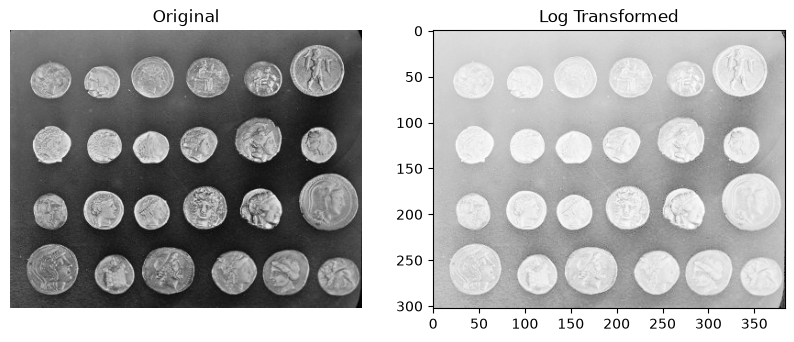

In [6]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img.astype(np.uint8), cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(log_transformed, cmap='gray')
plt.title('Log Transformed')

In [8]:
# Gamma transformation

In [9]:
normalized = img / 255.0

In [10]:
gamma_04 = np.power(normalized, 0.4) * 255
gamma_04 = np.clip(gamma_04, 0, 255)
gamma_04 = gamma_04.astype(np.uint8)

In [11]:
gamma_10 = np.power(normalized, 1.0) * 255
gamma_10 = np.clip(gamma_10, 0, 255)
gamma_10 = gamma_10.astype(np.uint8)

In [12]:
gamma_25 = np.power(normalized, 2.5) * 255
gamma_25 = np.clip(gamma_25, 0, 255)
gamma_25 = gamma_25.astype(np.uint8)

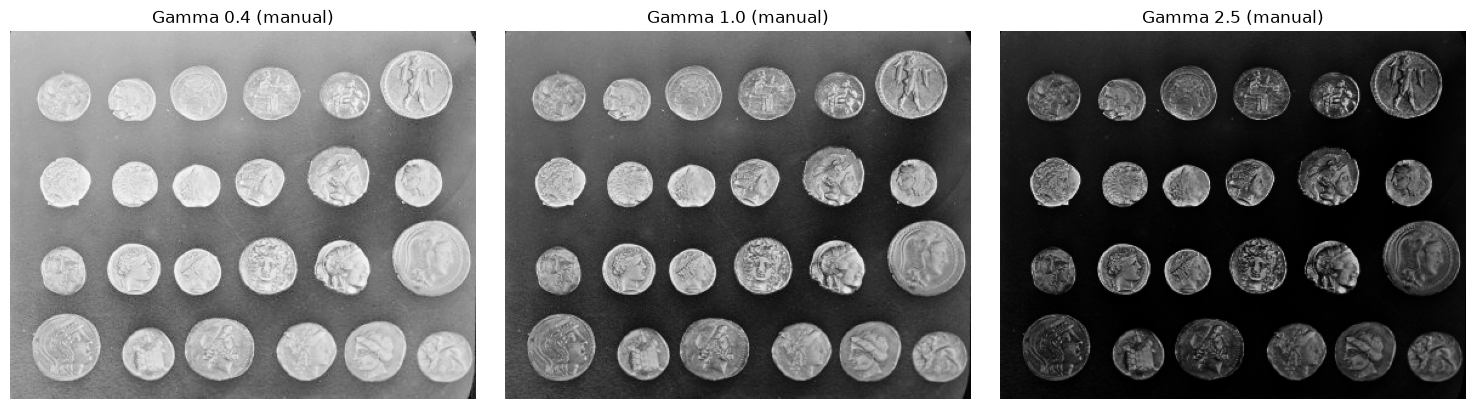

In [13]:
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.imshow(gamma_04, cmap='gray')
plt.title("Gamma 0.4 (manual)")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(gamma_10, cmap='gray')
plt.title("Gamma 1.0 (manual)")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(gamma_25, cmap='gray')
plt.title("Gamma 2.5 (manual)")
plt.axis('off')

plt.tight_layout()
plt.show()

In [14]:
# Piecewise Linear

In [15]:
r1, s1 = 70, 20
r2, s2 = 180, 230

In [16]:
piecewise_result = np.zeros_like(img)

region1 = img < r1
piecewise_result[region1] = (s1/r1) * img[region1]

region2 = (img >= r1) & (img <= r2)
piecewise_result[region2] = ((s2-s1) / (r2-r1)) * (img[region2] - r1) + s1

region3 = img > r2
piecewise_result[region3] = ((255-s2) / (255-r2)) * (img[region3] - r2) + s2

In [17]:
piecewise_result = np.clip(piecewise_result, 0, 255)
piecewise_result = piecewise_result.astype(np.uint8)

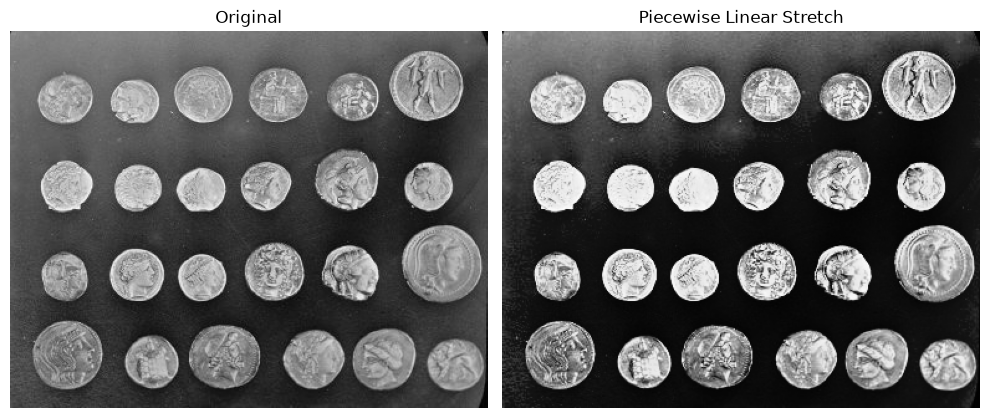

In [18]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img.astype(np.uint8), cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(piecewise_result, cmap='gray')
plt.title("Piecewise Linear Stretch")
plt.axis('off')

plt.tight_layout()
plt.show()

In [19]:
# Contrast stretching

In [39]:
stretched_cv2 = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)

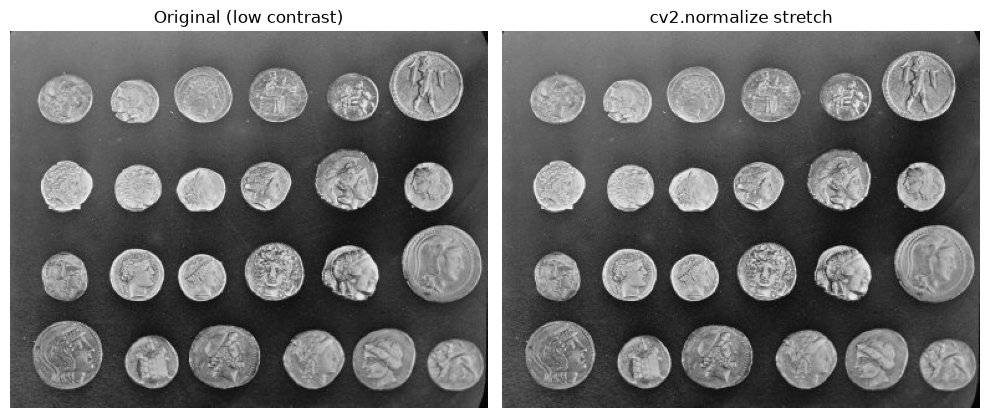

In [40]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img.astype(np.uint8), cmap="gray", vmin=0, vmax=255)
plt.title("Original (low contrast)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(stretched_cv2, cmap="gray", vmin=0, vmax=255)
plt.title("cv2.normalize stretch")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Histogram Processing

In [21]:
histogram, bin_edges = np.histogram(img.flatten(), bins=256, range=(0,256))

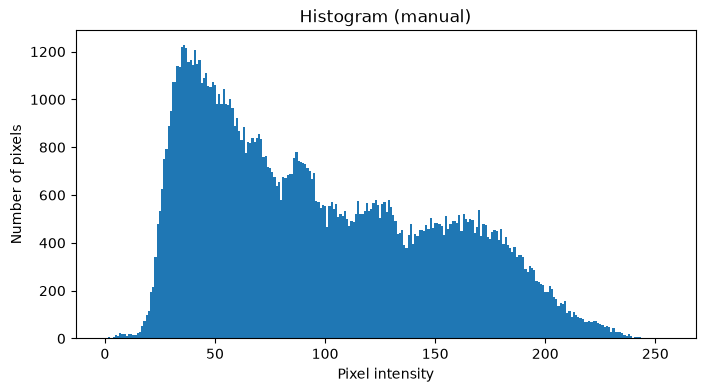

In [22]:
plt.figure(figsize=(8,4))
plt.bar(range(256), histogram, width=1)
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.title("Histogram (manual)")
plt.show()

In [23]:
eq_cv2 = cv2.equalizeHist(img)

In [26]:
cdf = histogram.cumsum()
cdf_min = cdf[cdf > 0].min()
cdf_normalized = np.round((cdf - cdf_min) * 255 / (cdf[-1] - cdf_min))
cdf_normalized = np.clip(cdf_normalized, 0, 255)

In [27]:
equalized_manual = np.interp(img.flatten(), np.arange(256), cdf_normalized)
equalized_manual = equalized_manual.reshape(img.shape).astype(np.uint8)

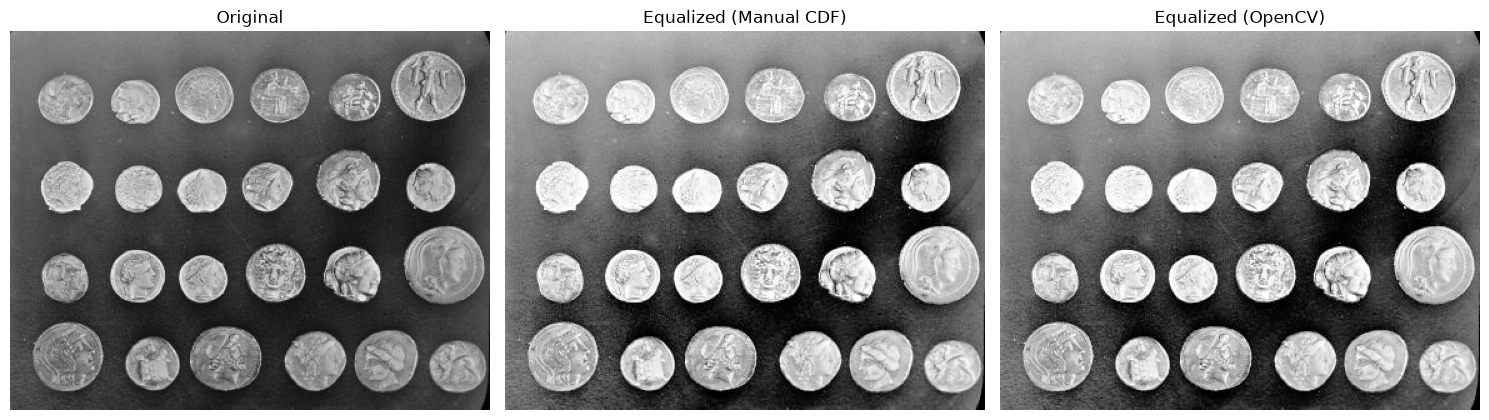

In [28]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(equalized_manual, cmap='gray')
plt.title("Equalized (Manual CDF)")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(eq_cv2, cmap='gray')
plt.title("Equalized (OpenCV)")
plt.axis('off')

plt.tight_layout()
plt.show()

In [29]:
# Image sharpening

In [30]:
lap_kernal = np.array([[0,1,0],
                      [1,-4,1],
                      [0,1,0]], dtype=np.float32)

In [31]:
lap_cv2 = cv2.Laplacian(img, cv2.CV_64F, ksize=3)
lap_cv2_display = (cv2.convertScaleAbs(lap_cv2))

In [32]:
sobel_kernal_x = np.array([[-1,0,1],
                          [-2,0,2],
                          [-1,0,1]], dtype=np.float32)

sobel_kernal_y = np.array([[-1,-2,-1],
                          [0,0,0],
                          [1,2,1]], dtype=np.float32)

In [33]:
sobel_x_cv2 = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y_cv2 = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel_cv2_magnitude = cv2.magnitude(sobel_x_cv2, sobel_y_cv2)
sobel_cv2_display = cv2.convertScaleAbs(sobel_cv2_magnitude)

In [34]:
sharpening_kernal = np.array([[0,-1,0],
                              [-1,5,-1],
                              [0,-1,0]], dtype=np.float32)

In [35]:
lap = cv2.Laplacian(img.astype(np.float32), cv2.CV_32F, ksize=1)
sharpening_cv2_display = np.clip(img.astype(np.float32) - lap, 0, 255).astype(np.uint8)

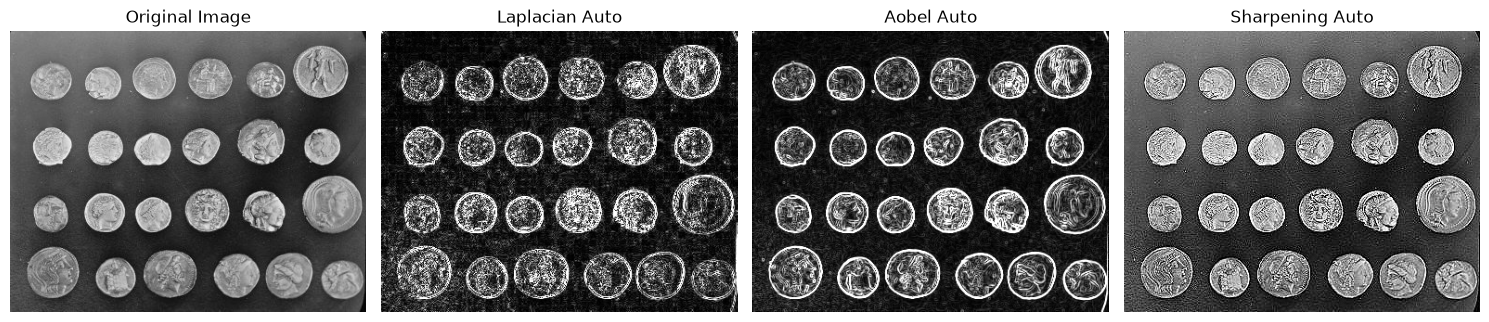

In [37]:
plt.figure(figsize=(15,4))

plt.subplot(1,4,1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(lap_cv2_display, cmap="gray", vmin=0, vmax=255)
plt.title("Laplacian Auto")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(sobel_cv2_display, cmap="gray", vmin=0, vmax=255)
plt.title("Aobel Auto")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(sharpening_cv2_display, cmap="gray", vmin=0, vmax=255)
plt.title("Sharpening Auto")
plt.axis("off")

plt.tight_layout()
plt.show()